# Airline Sentiment Classification by Fine-Tuning a Pretrained Transformer

Three-class sentiment classification (negative / neutral / positive) of US airline tweets, by
fine-tuning `distilbert-base-uncased` with a classification head and the lower layers frozen.

## Setup

In [2]:
import sys
from pathlib import Path


project_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src").is_dir())
sys.path.insert(0, str(project_root))

import torch.nn as nn

from src.config import TEXT_COL
from src.preprocessing import load_raw_data, preprocess_dataset
from src.tokenization import encode_labels, split_data, load_tokenizer, measure_max_length, make_loaders
from src.model import build_model
from src.train import set_seed, build_optimizer, train_model
from src.evaluate import plot_loss_curves, evaluate_model, plot_confusion_matrix

## 1. Data

The model is fed the original tweet text, with only HTML entities decoded. 

In [3]:
df = preprocess_dataset(load_raw_data())
df, class_names = encode_labels(df)
train_df, val_df, test_df = split_data(df)

Loaded 14640 rows and 15 columns from Tweets.csv
Rows in             : 14640
Empty after cleaning: 0
Duplicates removed  : 436
Rows out            : 14204
Label mapping: {'negative': 0, 'neutral': 1, 'positive': 2}
Train 11363 | Validation 1420 | Test 1421


## 2. Tokenization

In [4]:
tokenizer = load_tokenizer()
max_length = measure_max_length(train_df[TEXT_COL], tokenizer)

distilbert-base-uncased | vocabulary 30522 | model limit 512 tokens
Token lengths: mean 29.2 | median 31 | p95 43 | max 67
Truncated at 43: 521 tweets (4.6%)


## 3. Model

- **Pretrained encoder**: six transformer layers, hidden size 768, twelve attention heads.
- **Frozen parameters**: the embeddings and the three lowest transformer layers.

In [5]:
set_seed()
model = build_model(len(class_names))
print(model.config)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


distilbert-base-uncased: 66,955,779 parameters | trainable 21,856,515 (32.6%) | frozen embeddings + layers 0-2 of 6
DistilBertConfig {
  "activation": "gelu",
  "architectures": [
    "DistilBertForMaskedLM"
  ],
  "attention_dropout": 0.1,
  "bos_token_id": null,
  "dim": 768,
  "dropout": 0.1,
  "dtype": "float32",
  "eos_token_id": null,
  "hidden_dim": 3072,
  "id2label": {
    "0": "LABEL_0",
    "1": "LABEL_1",
    "2": "LABEL_2"
  },
  "initializer_range": 0.02,
  "label2id": {
    "LABEL_0": 0,
    "LABEL_1": 1,
    "LABEL_2": 2
  },
  "max_position_embeddings": 512,
  "model_type": "distilbert",
  "n_heads": 12,
  "n_layers": 6,
  "pad_token_id": 0,
  "qa_dropout": 0.1,
  "seq_classif_dropout": 0.2,
  "sinusoidal_pos_embds": false,
  "tie_weights_": true,
  "tie_word_embeddings": true,
  "transformers_version": "5.3.0",
  "vocab_size": 30522
}



In [6]:
train_loader, val_loader, test_loader = make_loaders(
    train_df, val_df, test_df, tokenizer, max_length, batch_size=32
)

## 4. Hyperparameters ##
1. batch_size = 32
2. optimizer = AdamW
3. learning_rate = 2e-5
4. weight_decay = 0.01
5. num_epochs = 3


In [7]:
set_seed()
model = build_model(len(class_names))
optimizer, scheduler = build_optimizer(model, train_loader, num_epochs=3)

model, train_losses, val_losses = train_model(
    model, train_loader, val_loader, nn.CrossEntropyLoss(), optimizer, scheduler,
    num_epochs=3, model_name="distilbert",
)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


distilbert-base-uncased: 66,955,779 parameters | trainable 21,856,515 (32.6%) | frozen embeddings + layers 0-2 of 6
AdamW lr=2e-05 | 1068 steps | 106 warmup steps
  step 50/356 | 9.5 min
  step 100/356 | 19.4 min
  step 150/356 | 29.2 min
  step 200/356 | 39.8 min
  step 250/356 | 54.4 min
  step 300/356 | 74.2 min
  step 350/356 | 83.8 min
Epoch 1/3 | Train loss 0.6152 | Val loss 0.4228 | 88.5 min
  step 50/356 | 8.2 min
  step 100/356 | 18.0 min
  step 150/356 | 27.9 min
  step 200/356 | 38.0 min
  step 250/356 | 47.9 min
  step 300/356 | 55.7 min
  step 350/356 | 63.1 min
Epoch 2/3 | Train loss 0.4159 | Val loss 0.3873 | 66.3 min
  step 50/356 | 7.2 min
  step 100/356 | 14.3 min
  step 150/356 | 21.3 min
  step 200/356 | 28.4 min
  step 250/356 | 35.2 min
  step 300/356 | 41.9 min
  step 350/356 | 48.7 min
Epoch 3/3 | Train loss 0.3715 | Val loss 0.3864 | 51.6 min
Best validation loss 0.3864 | weights saved to checkpoints/distilbert.pt


## 5. Learning curves

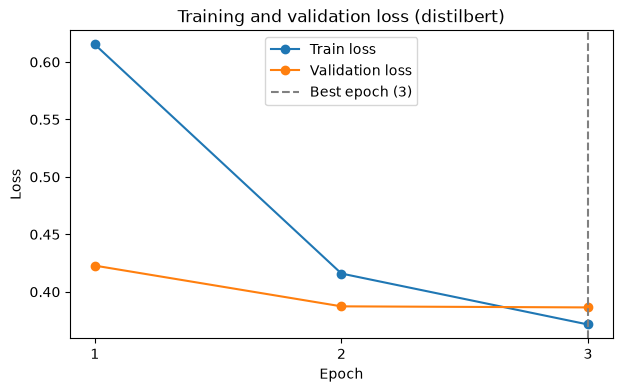

In [8]:
plot_loss_curves(train_losses, val_losses, model_name="distilbert")

## 6. Evaluation on the test set


Accuracy: 0.8255

              precision    recall  f1-score   support

    negative     0.8834    0.9029    0.8930       906
     neutral     0.6654    0.6020    0.6321       294
    positive     0.7773    0.8054    0.7911       221

    accuracy                         0.8255      1421
   macro avg     0.7754    0.7701    0.7721      1421
weighted avg     0.8218    0.8255    0.8232      1421



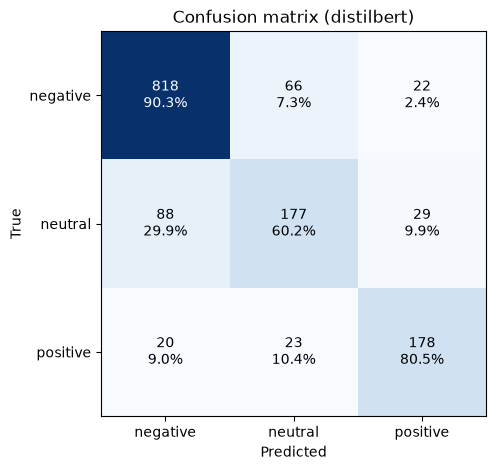

In [9]:
y_true, y_pred = evaluate_model(model, test_loader, class_names)
plot_confusion_matrix(y_true, y_pred, class_names, model_name="distilbert")